# Dinámica longitudinal de un avión de ala fija con `python-control`

En este cuaderno usamos la librería **python-control** (`pip install control`) para:

1. Definir el avión como **sistema no lineal** (`ct.nlsys`) y calcular el **trimado** (`ct.find_operating_point`).
2. **Linealizar** el modelo (`ct.linearize`) y ver sus modos propios (`ct.damp`).
3. Simular la respuesta a una **perturbación** (`ct.input_output_response`).
4. Añadir un **actuador** de primer orden (`ct.ss`).
5. Cerrar un lazo **PID de ángulo de asiento** conectando bloques con `ct.interconnect`.
6. Cerrar un lazo de **altitude hold** en cascada.

La idea de python-control es trabajar con **bloques con nombre**: cada sistema tiene entradas, salidas y
estados con nombre, y `ct.interconnect` conecta automáticamente las señales que se llaman igual.

**Importante:** el fichero `dinamica_longitudinal.py` debe estar en la misma carpeta que este cuaderno.

## 0. Importar librerías

In [1]:
import numpy as np                 # cálculo numérico
import matplotlib.pyplot as plt    # gráficas
import control as ct               # librería python-control

# Del fichero del modelo importamos: la función que crea el avión y la de trimado
from dinamica_longitudinal import crear_avion, trimado

print("Versión de python-control:", ct.__version__)

Versión de python-control: 0.10.2


## 1. El avión como sistema no lineal

`crear_avion()` envuelve el modelo `f(x, u)` en un objeto `ct.nlsys`:

- **Estados:** x, z, V, alpha, theta, q
- **Entradas:** Acc (gases), Delev (timón)
- **Salidas:** xpos, h, V, alpha, theta, q, h_dot (lo que miden los sensores)

In [2]:
avion = crear_avion()
print(avion)

<NonlinearIOSystem>: avion
Inputs (2): ['Acc', 'Delev']
Outputs (7): ['xpos', 'h', 'V', 'alpha', 'theta', 'q', 'h_dot']
States (6): ['x', 'z', 'V', 'alpha', 'theta', 'q']

Update: <function _ecuacion_estado at 0x7fc78fb0b7e0>
Output: <function _salidas at 0x7fc78fb21800>


## 2. Punto de trimado

Vuelo horizontal a velocidad y altitud constantes. `trimado()` usa `ct.find_operating_point`
fijando z, V y q = 0, e imponiendo dV = dα = dq = 0 y velocidad vertical nula.

In [3]:
# Condición de vuelo de crucero
V_crucero = 60.0     # velocidad [m/s]  (~117 nudos)
h_crucero = 2000.0   # altitud [m]

x_trim, u_trim = trimado(avion, V_crucero, h_crucero)
Acc_trim, de_trim = u_trim        # gases y timón de trimado
theta_trim = x_trim[4]            # ángulo de asiento de trimado

print("Estado de trimado:")
print("  V     = %.2f m/s"   % x_trim[2])
print("  alpha = %.2f grados" % np.degrees(x_trim[3]))
print("  theta = %.2f grados" % np.degrees(x_trim[4]))
print("Entrada de trimado:")
print("  Acc   = %.3f"        % Acc_trim)
print("  Delev = %.2f grados" % np.degrees(de_trim))

Estado de trimado:
  V     = 60.00 m/s
  alpha = 0.67 grados
  theta = 0.67 grados
Entrada de trimado:
  Acc   = 0.489
  Delev = -1.14 grados


## 3. Linealización y modos propios

`ct.linearize` calcula el modelo lineal  ẋ = A·Δx + B·Δu  alrededor del trimado.
Nos quedamos con los estados que de verdad tienen dinámica (V, α, θ, q): x y z solo integran la velocidad
y dan autovalores nulos.

`ct.damp` muestra, para cada polo, su amortiguamiento ζ y su frecuencia natural ωn.

In [4]:
# Linealizamos el modelo completo alrededor del trimado
lin = ct.linearize(avion, x_trim, u_trim)

# Nos quedamos con los estados V, alpha, theta, q (índices 2 a 5)
idx = [2, 3, 4, 5]
A = lin.A[np.ix_(idx, idx)]
B = lin.B[idx, :]
lin4 = ct.ss(A, B, np.eye(4), np.zeros((4, 2)),
             states=['V', 'alpha', 'theta', 'q'], inputs=['Acc', 'Delev'],
             outputs=['V', 'alpha', 'theta', 'q'], name='avion_lineal')

print("Matriz A:")
print(np.round(A, 4))
print()
ct.damp(lin4);

Matriz A:
[[-3.4400e-02  4.3557e+00 -9.8100e+00 -5.1200e-02]
 [-5.4000e-03 -2.3373e+00 -0.0000e+00  9.7820e-01]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]
 [ 0.0000e+00 -2.0514e+01  0.0000e+00 -3.5488e+00]]

    Eigenvalue (pole)       Damping     Frequency
    -2.946    +4.438j         0.553         5.327
    -2.946    -4.438j         0.553         5.327
  -0.01474   +0.1959j       0.07504        0.1965
  -0.01474   -0.1959j       0.07504        0.1965


Corto periodo : wn = 5.327 rad/s, zeta = 0.553, periodo = 1.4 s
Fugoide       : wn = 0.196 rad/s, zeta = 0.075, periodo = 32.1 s


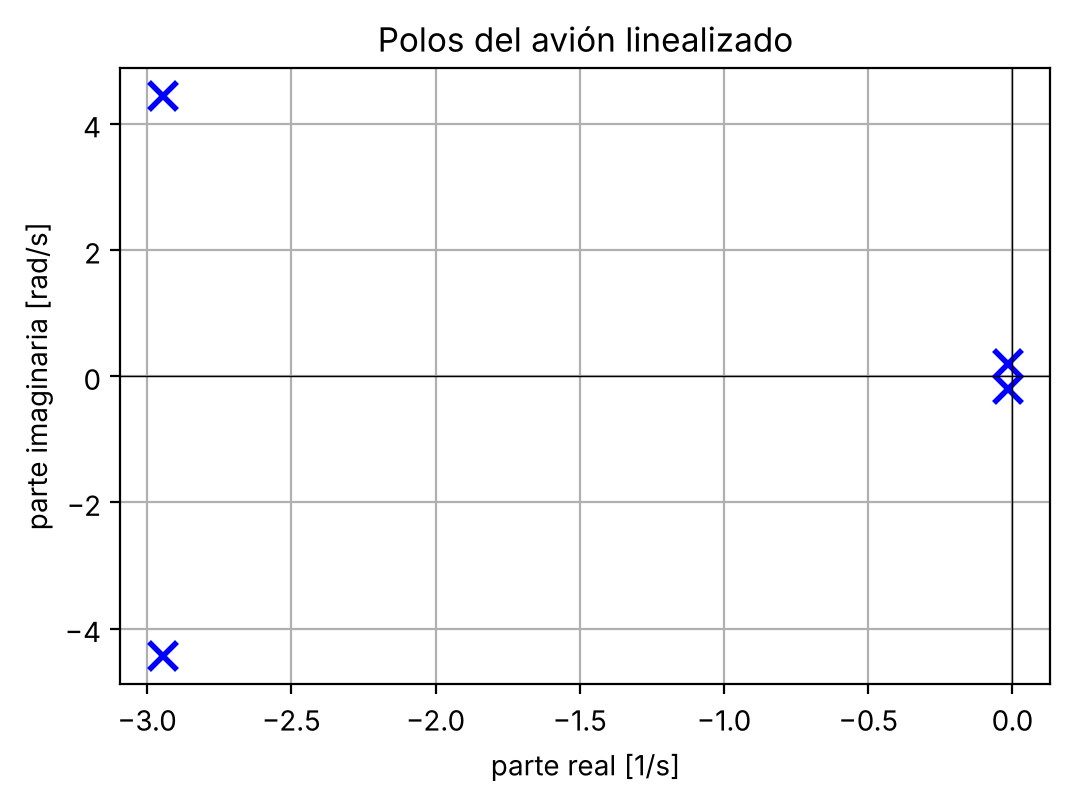

In [5]:
# Identificamos los dos modos a partir de los polos
polos = lin4.poles()
for p in polos[polos.imag > 0]:           # un polo de cada par complejo
    wn = abs(p)                           # frecuencia natural [rad/s]
    zeta = -p.real / wn                   # amortiguamiento
    periodo = 2 * np.pi / p.imag          # periodo de la oscilación [s]
    nombre = 'Corto periodo' if wn > 1 else 'Fugoide'
    print("%-14s: wn = %.3f rad/s, zeta = %.3f, periodo = %.1f s" % (nombre, wn, zeta, periodo))

# Mapa de polos en el plano complejo
plt.figure(figsize=(6, 4))
plt.plot(polos.real, polos.imag, 'bx', markersize=10, markeredgewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.xlabel('parte real [1/s]'); plt.ylabel('parte imaginaria [rad/s]'); plt.grid(True)
plt.title('Polos del avión linealizado')
plt.show()

- **Corto periodo**: rápido (periodo ~1,4 s) y bien amortiguado (ζ ≈ 0,55). Afecta sobre todo a α y q.
- **Fugoide**: lento (periodo ~32 s) y poco amortiguado (ζ ≈ 0,07). Intercambio de velocidad por altitud.

## 4. Respuesta a una perturbación (lazo abierto)

Partimos del trimado, aumentamos la velocidad inicial y dejamos los mandos fijos en sus valores de trimado.
Simulamos con `ct.input_output_response(sistema, T, U, X0)`.

### Parámetros (modifícalos aquí)

In [6]:
t_final_pert = 100.0   # duración de la simulación [s]
dt_pert      = 0.05    # intervalo entre puntos guardados [s]
dV_pert      = 5.0     # perturbación en velocidad [m/s]
dalpha_pert  = 0.0     # perturbación en ángulo de ataque [grados] (prueba con 2)
dq_pert      = 0.0     # perturbación en velocidad de cabeceo [grados/s] (prueba con 5)

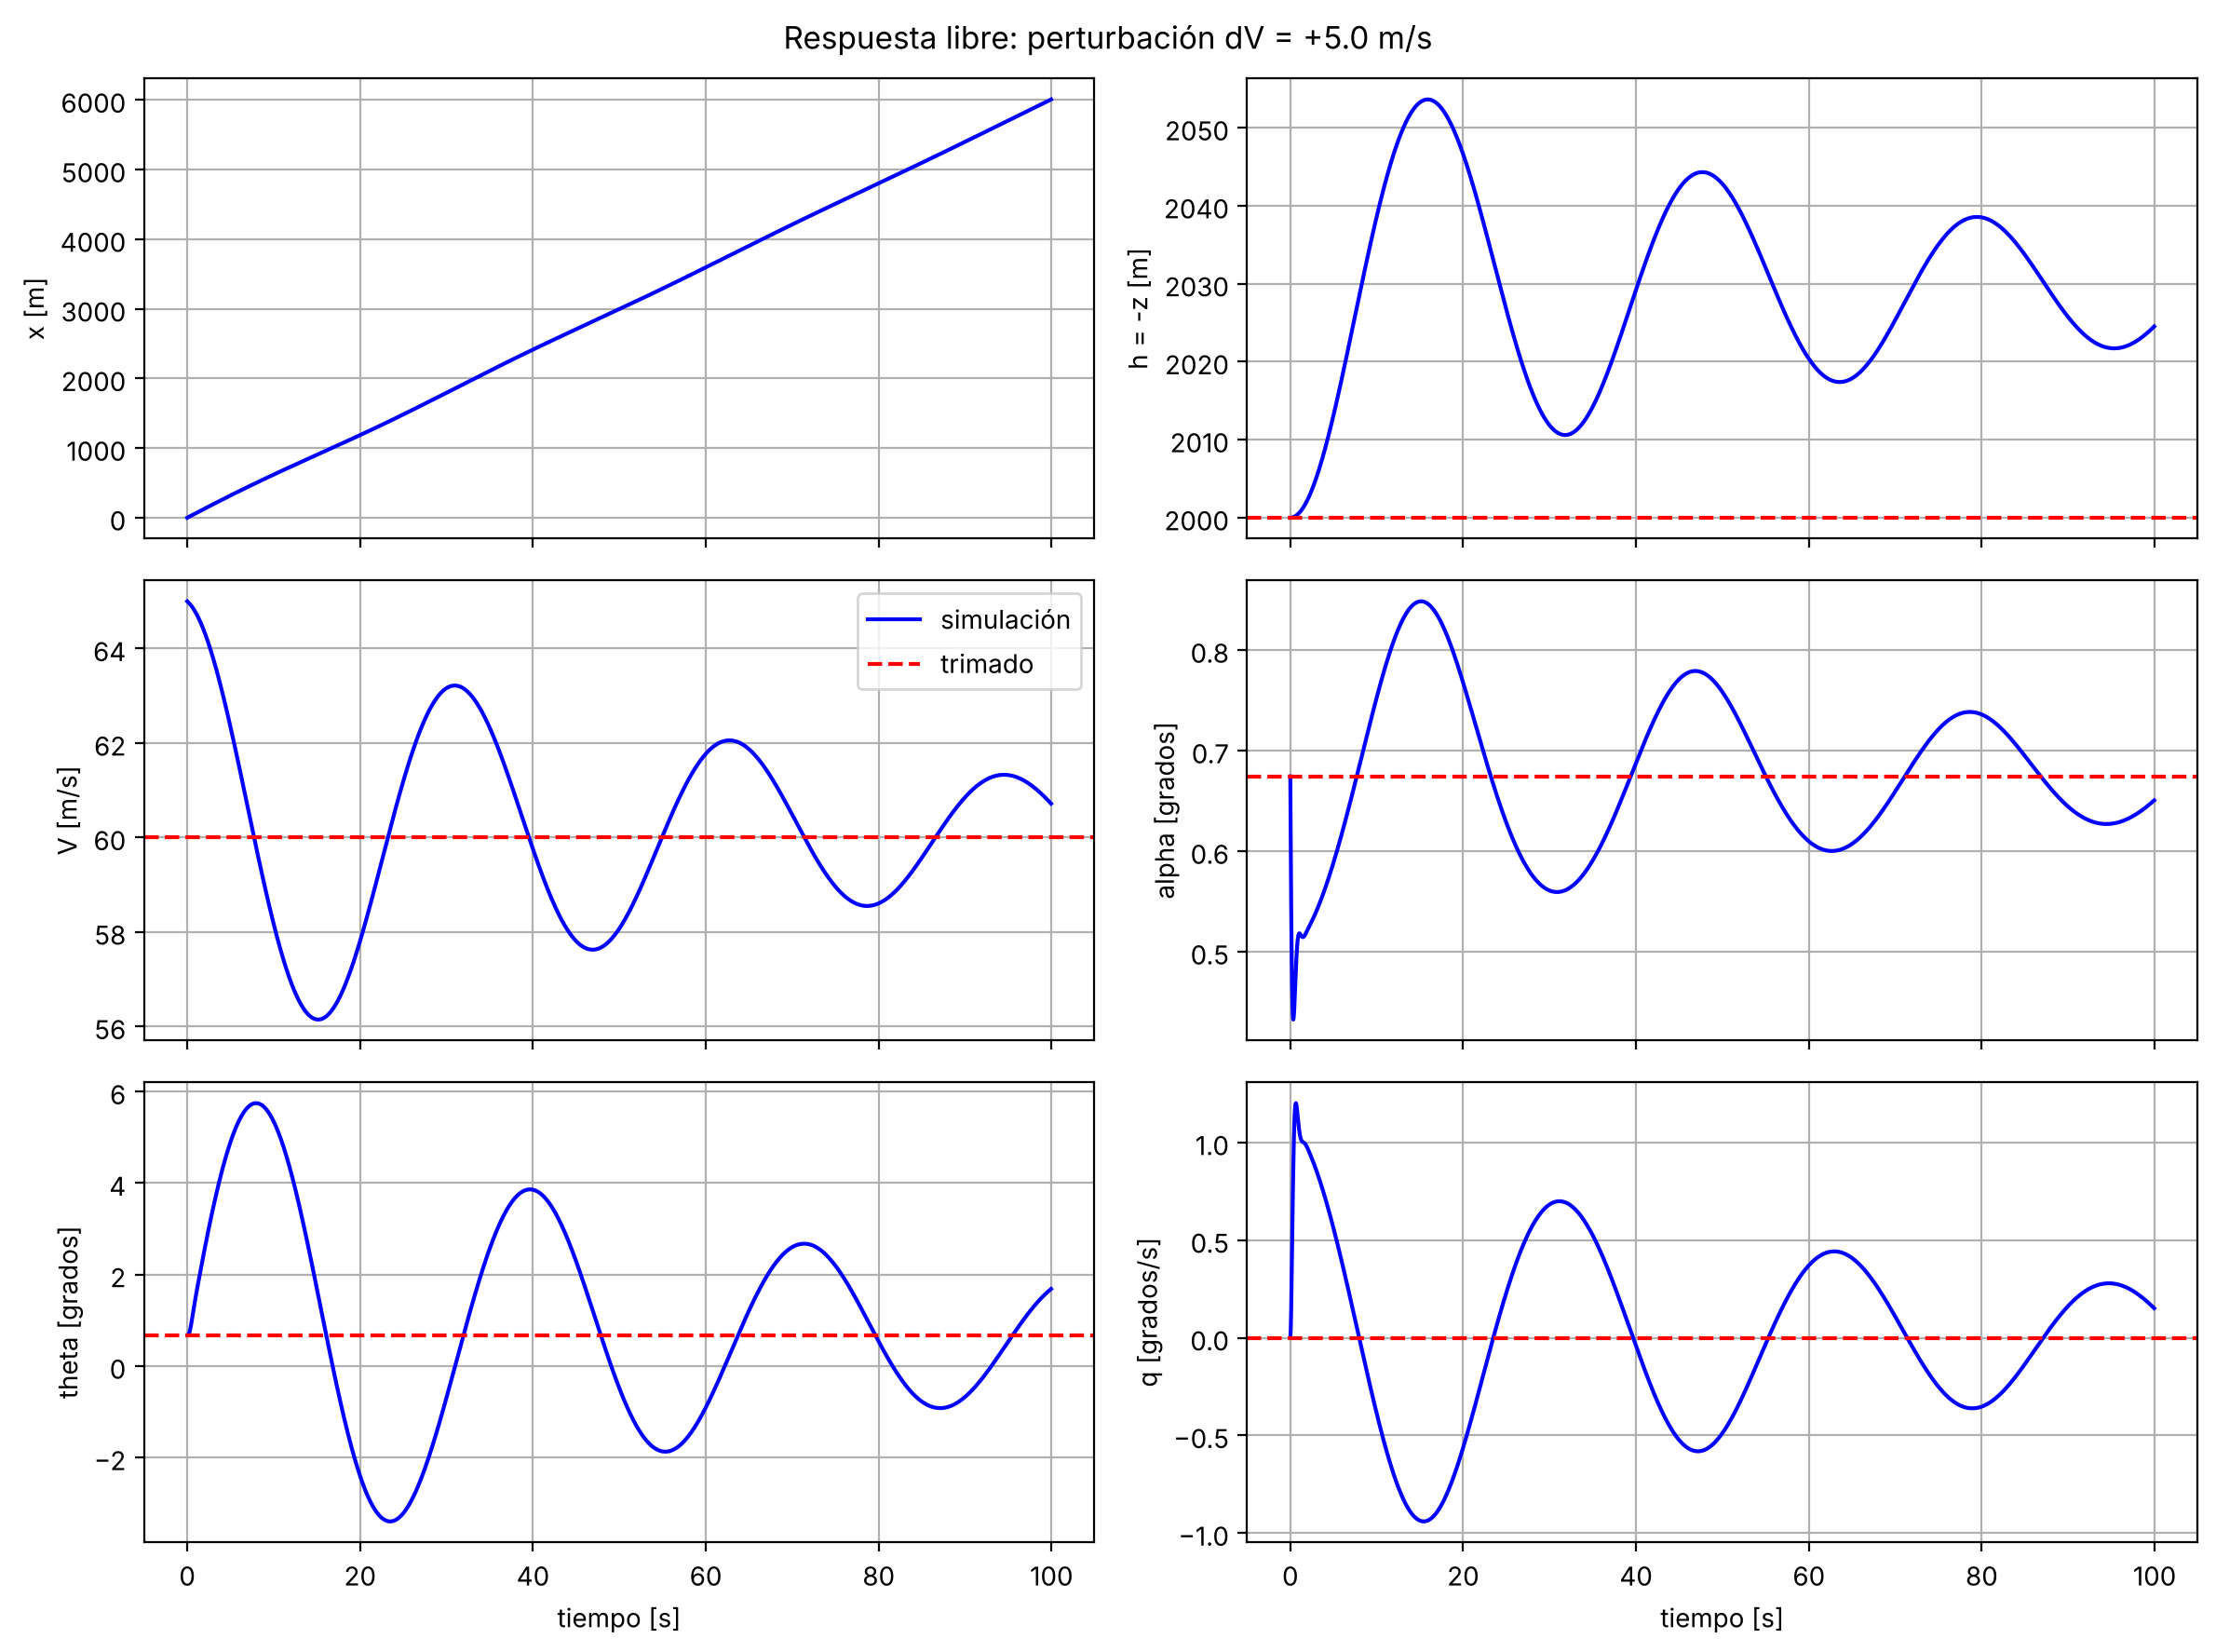

In [7]:
# Vector de tiempos
T = np.arange(0, t_final_pert, dt_pert)

# Entradas constantes e iguales al trimado: una fila por entrada, una columna por instante
U = np.vstack([Acc_trim * np.ones_like(T),
               de_trim  * np.ones_like(T)])

# Estado inicial = trimado + perturbación
x0 = x_trim.copy()
x0[2] += dV_pert
x0[3] += np.radians(dalpha_pert)
x0[5] += np.radians(dq_pert)

# Simulación no lineal
resp = ct.input_output_response(avion, T, U, x0,
                                solve_ivp_kwargs={'max_step': 0.05})

# resp.time -> tiempos, resp.states -> estados (una fila por estado)
t = resp.time
X = resp.states

# --- Dibujar las 6 variables de estado ---
nombres = ['x [m]', 'h = -z [m]', 'V [m/s]', 'alpha [grados]', 'theta [grados]', 'q [grados/s]']
datos = [X[0], -X[1], X[2], np.degrees(X[3]), np.degrees(X[4]), np.degrees(X[5])]
trim  = [None, -x_trim[1], x_trim[2], np.degrees(x_trim[3]), np.degrees(x_trim[4]), 0.0]

fig, ejes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
ejes = ejes.flatten()
for i in range(6):
    ejes[i].plot(t, datos[i], 'b', label='simulación')
    if trim[i] is not None:
        ejes[i].axhline(trim[i], color='r', linestyle='--', label='trimado')
    ejes[i].set_ylabel(nombres[i])
    ejes[i].grid(True)
ejes[2].legend()
ejes[4].set_xlabel('tiempo [s]'); ejes[5].set_xlabel('tiempo [s]')
fig.suptitle('Respuesta libre: perturbación dV = %+.1f m/s' % dV_pert)
plt.tight_layout()
plt.show()

Se ve claramente el **fugoide** (oscilación de ~32 s entre V y h) y, al principio, un transitorio muy
rápido en α y q que corresponde al **corto periodo**. Coincide con lo que predecía la linealización.

---
# PARTE 2: Actuador y control

## 5. Actuador del timón: retardo de primer orden

$$\frac{\Delta_e(s)}{\Delta_{e,cmd}(s)} = \frac{1}{\tau s + 1}
\qquad\Longleftrightarrow\qquad
\dot\delta_e = -\frac{1}{\tau}\,\delta_e + \frac{1}{\tau}\,\delta_{e,cmd}$$

Es un sistema **lineal**, así que lo creamos con `ct.ss` (espacio de estados).
Lo escribimos así para que su estado sea directamente la deflexión real del timón.

- Entrada: `de_cmd` (timón pedido)
- Salida: `Delev` (timón real) → como se llama igual que la entrada del avión, `interconnect` los conecta solos.

La función `crear_actuador(tau)` se usará en las dos simulaciones con control.

<TransferFunction>: actuador$converted
Inputs (1): ['de_cmd']
Outputs (1): ['Delev']

    10
  ------
  s + 10


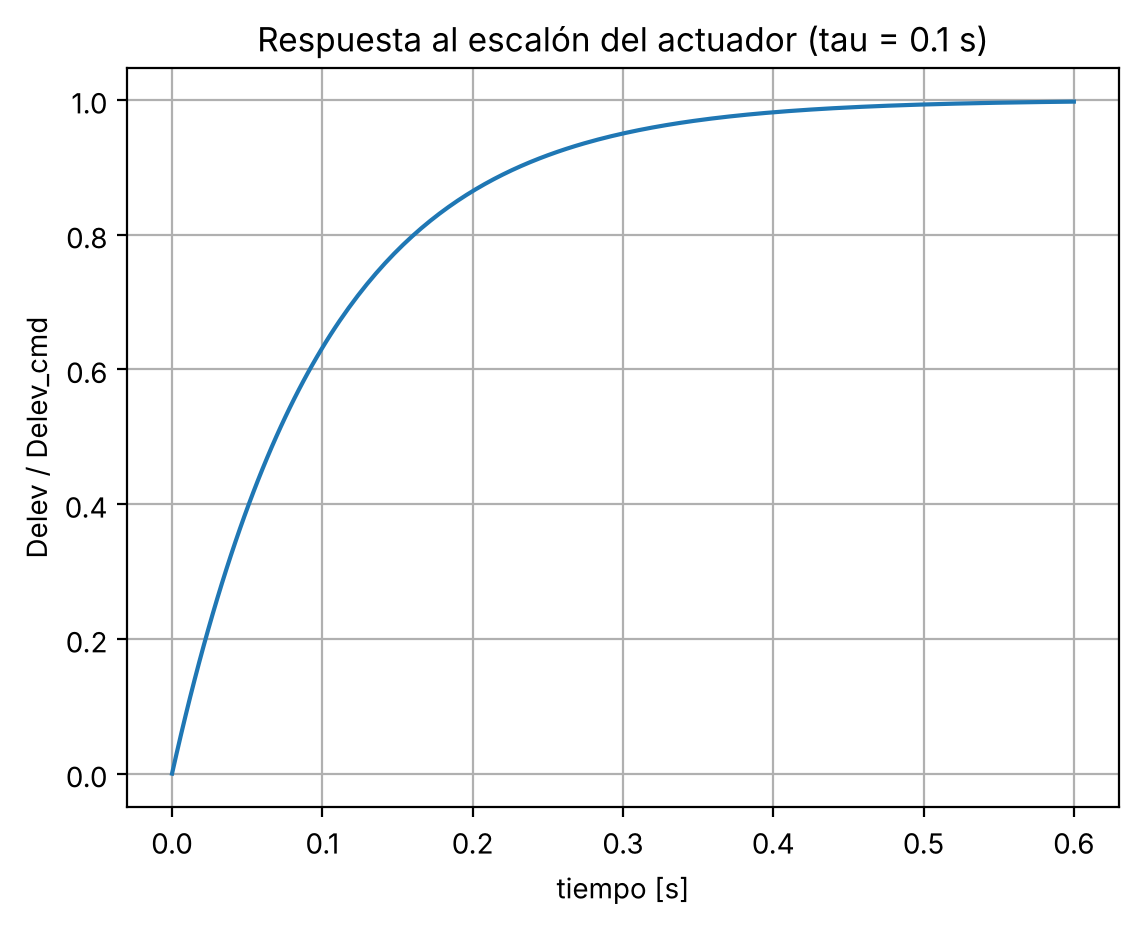

In [8]:
def crear_actuador(tau):
    """Actuador de primer orden 1/(tau*s + 1) en espacio de estados."""
    return ct.ss(-1.0 / tau, 1.0 / tau, 1.0, 0.0,      # A, B, C, D
                 inputs='de_cmd', outputs='Delev', states='Delev_real',
                 name='actuador')

# Ejemplo: respuesta a un escalón unitario del actuador con tau = 0.1 s
act = crear_actuador(0.1)
print(ct.tf(act))   # función de transferencia equivalente
r = ct.step_response(act, T=np.linspace(0, 0.6, 200))
plt.plot(r.time, r.outputs)
plt.xlabel('tiempo [s]'); plt.ylabel('Delev / Delev_cmd'); plt.grid(True)
plt.title('Respuesta al escalón del actuador (tau = 0.1 s)')
plt.show()

### Funciones auxiliares

- `senal(resp, nombre)`: extrae una señal de la respuesta por su nombre.
- `dibujar(...)`: dibuja las variables principales de una simulación con control.

In [9]:
def senal(resp, nombre):
    """Devuelve la salida llamada 'nombre' de una respuesta de python-control."""
    i = resp.output_labels.index(nombre)
    return resp.outputs[i]


def dibujar(resp, titulo, theta_ref=None, h_ref=None):
    """Dibuja h, V, theta, alpha, q y el timón (pedido y real)."""
    t = resp.time
    fig, ejes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
    ejes = ejes.flatten()

    ejes[0].plot(t, senal(resp, 'h'), 'b', label='h')
    if h_ref is not None:
        ejes[0].plot(t, h_ref, 'r--', label='referencia'); ejes[0].legend()
    ejes[0].set_ylabel('h [m]')

    ejes[1].plot(t, senal(resp, 'V'), 'b')
    ejes[1].set_ylabel('V [m/s]')

    ejes[2].plot(t, np.degrees(senal(resp, 'theta')), 'b', label='theta')
    if theta_ref is not None:
        ejes[2].plot(t, np.degrees(theta_ref), 'r--', label='referencia'); ejes[2].legend()
    ejes[2].set_ylabel('theta [grados]')

    ejes[3].plot(t, np.degrees(senal(resp, 'alpha')), 'b')
    ejes[3].set_ylabel('alpha [grados]')

    ejes[4].plot(t, np.degrees(senal(resp, 'q')), 'b')
    ejes[4].set_ylabel('q [grados/s]')
    ejes[4].set_xlabel('tiempo [s]')

    ejes[5].plot(t, np.degrees(senal(resp, 'de_cmd')), 'r', label='pedido (cmd)')
    ejes[5].plot(t, np.degrees(senal(resp, 'Delev')), 'b', label='real (actuador)')
    ejes[5].set_ylabel('Delev [grados]'); ejes[5].set_xlabel('tiempo [s]')
    ejes[5].legend()

    for e in ejes:
        e.grid(True)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## 6. Control PID del ángulo de asiento θ

$$\delta_{e,cmd} = \delta_{e,trim} - \left( K_p\, e + K_i \int e\, dt - K_d\, q \right),
\qquad e = \theta_{ref} - \theta$$

- El **signo menos** es porque un δe positivo (timón abajo) hace picar el avión.
- Como derivada usamos **−q** (= de/dt con referencia constante): se evita el pico al derivar un escalón.
- El timón se **satura** a ±δe,max y, mientras satura, el integrador se congela (*anti-windup*).

Como el PID tiene saturación (no lineal), lo creamos con `ct.nlsys`. Su único estado es la integral del error.
Los valores de las ganancias se pasan como **parámetros** (`params`) del sistema.

Diagrama de bloques que construye `ct.interconnect`:

```
theta_ref ──► [ PID ] ──de_cmd──► [ actuador ] ──Delev──► [ avión ] ──► theta, q, h, V ...
                ▲                                    Acc ──►    │
                └──────────────── theta, q ─────────────────────┘
```

### Parámetros (modifícalos aquí)

In [10]:
# ===================== SIMULACIÓN =====================
t_final = 60.0      # duración [s]
dt      = 0.01      # intervalo entre puntos guardados [s]

# ===================== ACTUADOR =====================
tau     = 0.1                 # constante de tiempo del actuador [s]
de_max  = np.radians(25)      # saturación del timón [rad]

# ===================== REFERENCIA DE THETA =====================
t_escalon  = 5.0              # instante del escalón [s]
dtheta_ref = np.radians(5)    # tamaño del escalón [rad] (+5 grados)

# ===================== GANANCIAS DEL PID =====================
Kp = 2.0    # proporcional [rad timón / rad error]
Ki = 0.5    # integral     [1/s]
Kd = 0.5    # derivativa   [s]

In [11]:
# --- Bloque PID de theta (sistema no lineal con un estado: la integral del error) ---

def pid_theta_salida(t, x, u, p):
    """Salida del PID: timón pedido (saturado)."""
    theta_ref, theta, q = u              # entradas del bloque
    integral = x[0]                      # estado del bloque
    error = theta_ref - theta
    de = p['de_trim'] - (p['Kp'] * error + p['Ki'] * integral - p['Kd'] * q)
    return [np.clip(de, -p['de_max'], p['de_max'])]

def pid_theta_estado(t, x, u, p):
    """Derivada del estado del PID: d(integral)/dt = error (salvo si satura)."""
    theta_ref, theta, q = u
    integral = x[0]
    error = theta_ref - theta
    de = p['de_trim'] - (p['Kp'] * error + p['Ki'] * integral - p['Kd'] * q)
    if abs(de) < p['de_max']:
        return [error]                   # integramos normalmente
    else:
        return [0.0]                     # anti-windup: congelamos la integral

def crear_pid_theta(Kp, Ki, Kd, de_trim, de_max):
    return ct.nlsys(pid_theta_estado, pid_theta_salida,
                    inputs=['theta_ref', 'theta', 'q'], outputs=['de_cmd'],
                    states=['int_e'], name='pid_theta',
                    params=dict(Kp=Kp, Ki=Ki, Kd=Kd, de_trim=de_trim, de_max=de_max))

# --- Creamos los bloques con los parámetros de arriba ---
actuador  = crear_actuador(tau)
pid_theta = crear_pid_theta(Kp, Ki, Kd, de_trim, de_max)

# --- Conectamos los bloques: se unen las señales con el mismo nombre ---
lazo_theta = ct.interconnect(
    [avion, actuador, pid_theta],
    inplist=['theta_ref', 'Acc'],  inputs=['theta_ref', 'Acc'],          # entradas externas
    outlist=['h', 'V', 'alpha', 'theta', 'q', 'de_cmd', 'Delev'],         # señales a guardar
    outputs=['h', 'V', 'alpha', 'theta', 'q', 'de_cmd', 'Delev'],
    name='lazo_theta', check_unused=False)

print(lazo_theta)

<InterconnectedSystem>: lazo_theta
Inputs (2): ['theta_ref', 'Acc']
Outputs (7): ['h', 'V', 'alpha', 'theta', 'q', 'de_cmd', 'Delev']
States (8): ['avion_x', 'avion_z', 'avion_V', 'avion_alpha', 'avion_theta', 'avion_q', 'actuador_Delev_real', 'pid_theta_int_e']

Subsystems (3):
 * <NonlinearIOSystem avion: ['Acc', 'Delev'] -> ['xpos', 'h', 'V', 'alpha',
    'theta', 'q', 'h_dot']>
 * <StateSpace actuador: ['de_cmd'] -> ['Delev']>
 * <NonlinearIOSystem pid_theta: ['theta_ref', 'theta', 'q'] -> ['de_cmd']>

Connections:
 * avion.Acc <- Acc
 * avion.Delev <- actuador.Delev
 * actuador.de_cmd <- pid_theta.de_cmd
 * pid_theta.theta_ref <- theta_ref
 * pid_theta.theta <- avion.theta
 * pid_theta.q <- avion.q

Outputs:
 * h <- avion.h
 * V <- avion.V
 * alpha <- avion.alpha
 * theta <- avion.theta
 * q <- avion.q
 * de_cmd <- pid_theta.de_cmd
 * Delev <- actuador.Delev


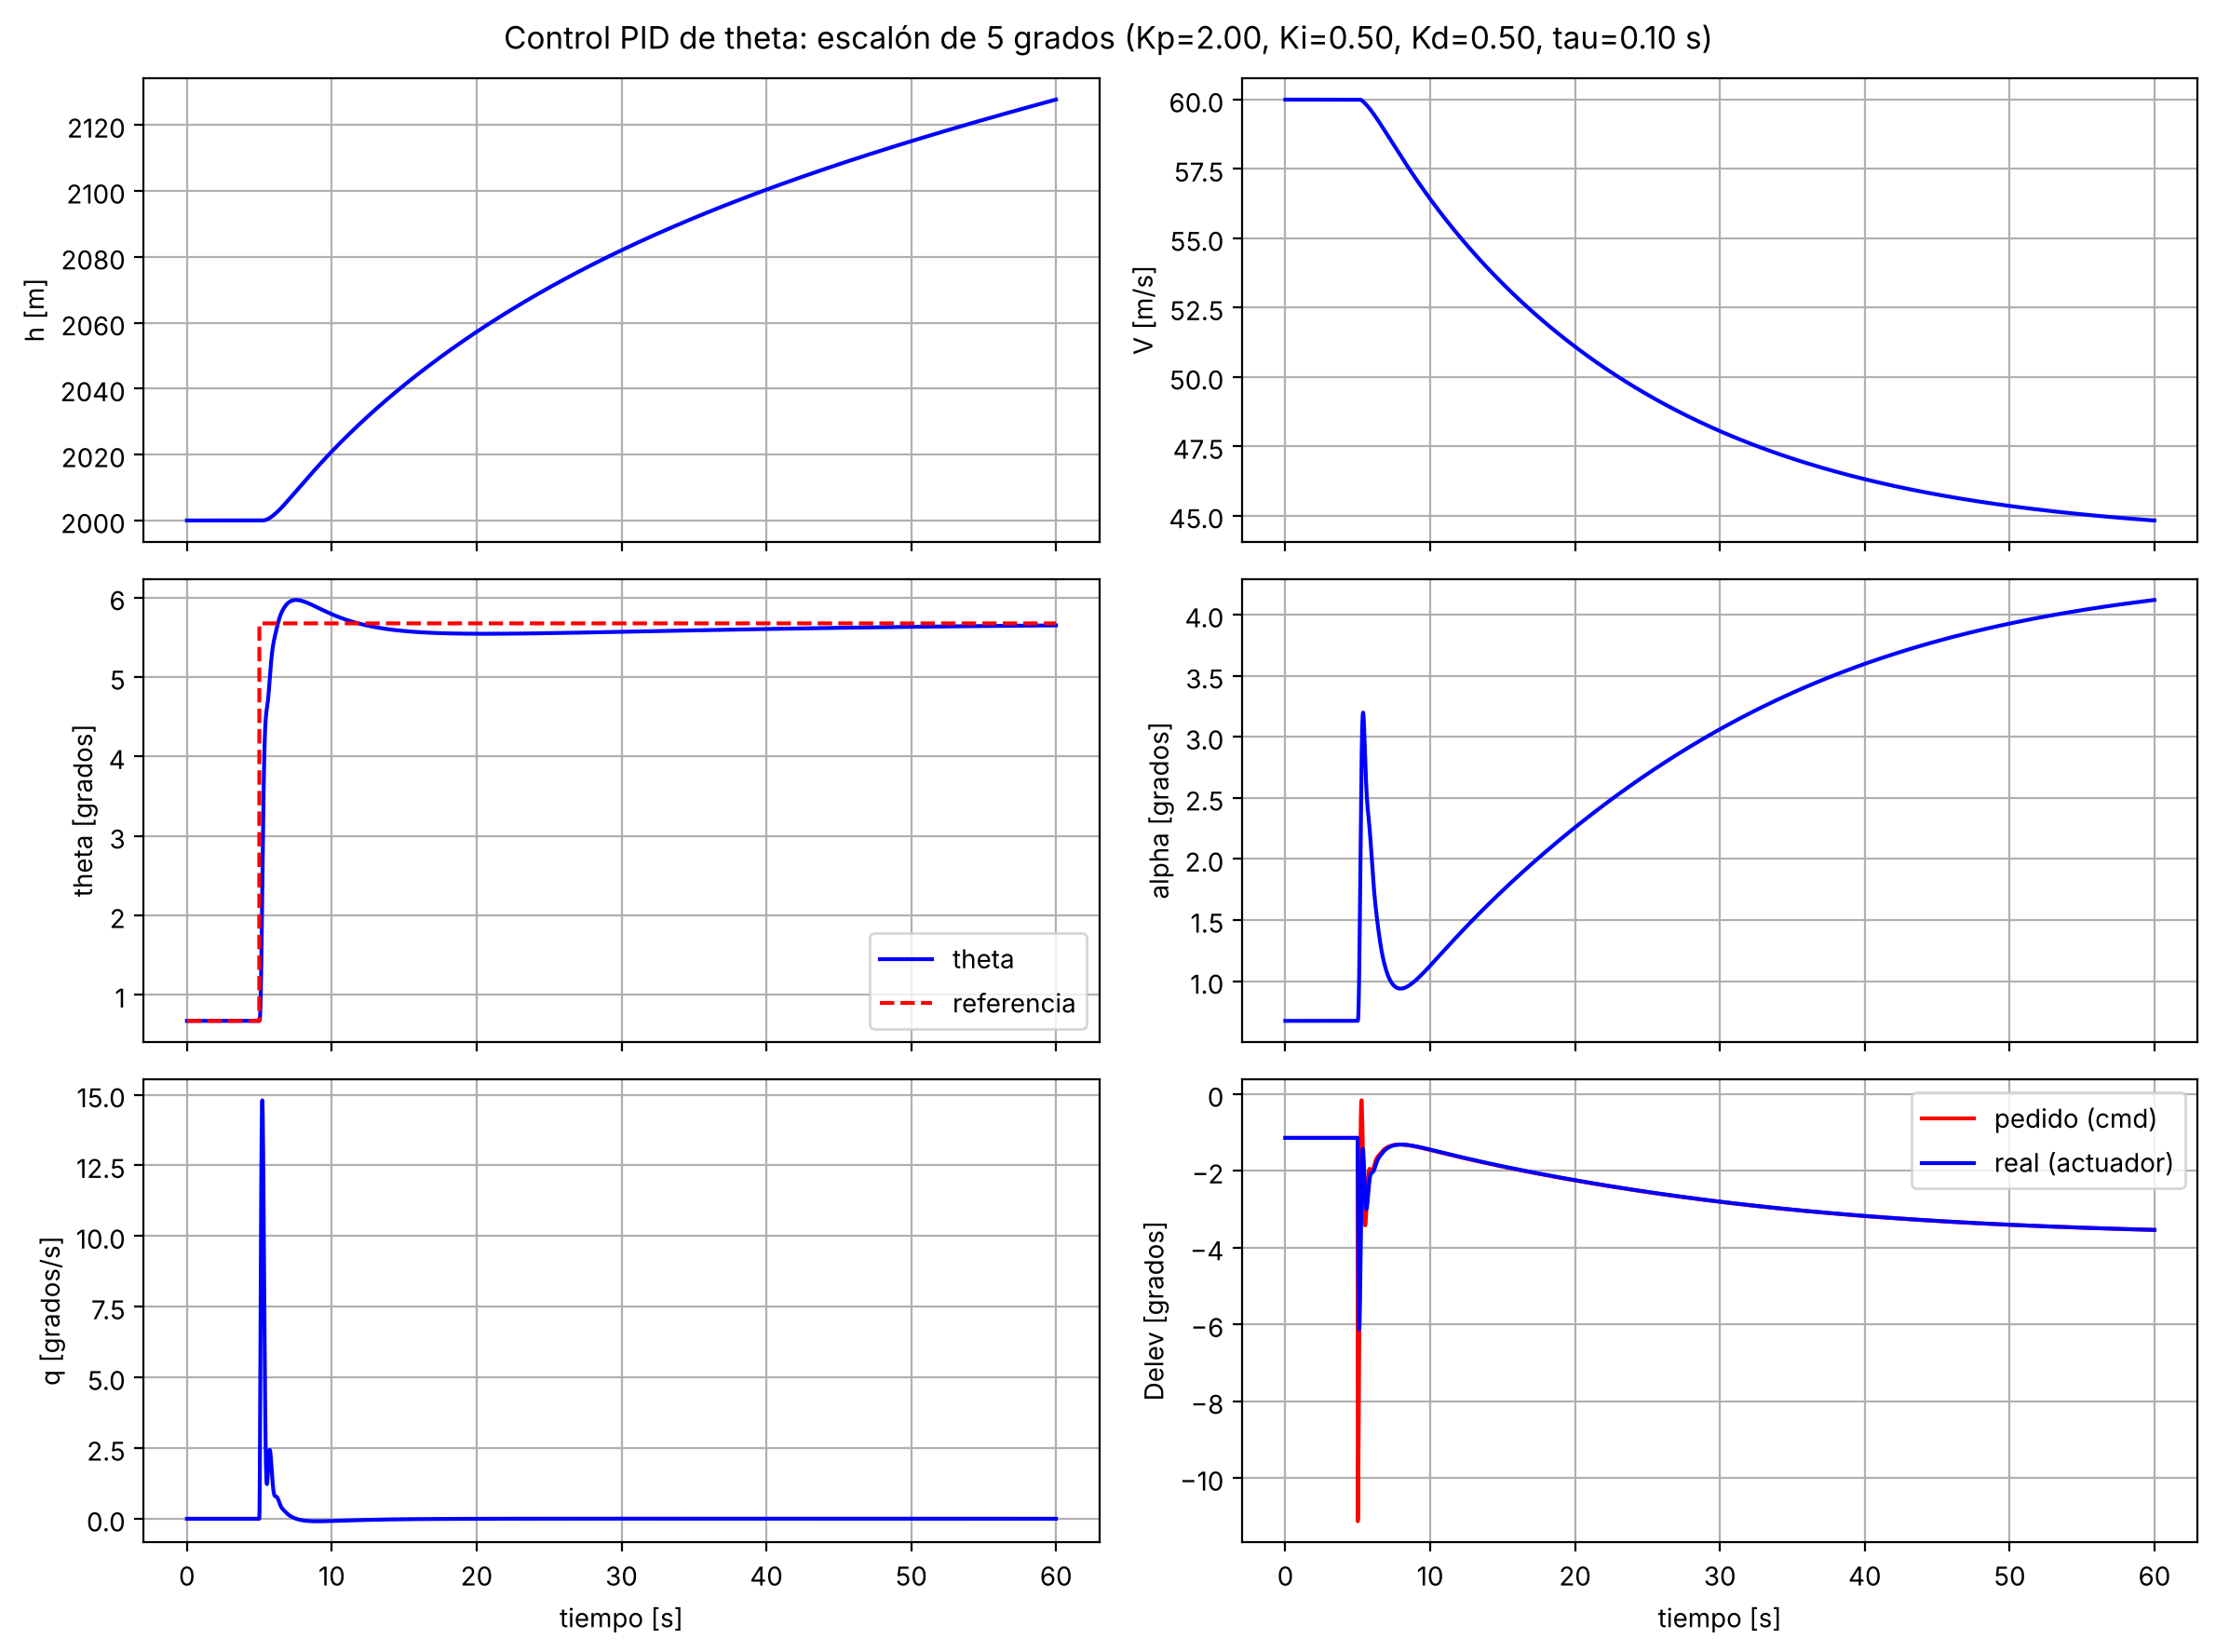

In [12]:
# --- Señales de entrada ---
T = np.arange(0, t_final, dt)
theta_ref = theta_trim + dtheta_ref * (T >= t_escalon)   # escalón en t_escalon
Acc = Acc_trim * np.ones_like(T)                         # gases fijos
U = np.vstack([theta_ref, Acc])

# --- Estado inicial: el orden es el de los bloques -> [avión (6), actuador (1), PID (1)] ---
X0 = np.concatenate([x_trim, [de_trim], [0.0]])

# --- Simulación no lineal ---
resp_theta = ct.input_output_response(lazo_theta, T, U, X0,
                                      solve_ivp_kwargs={'max_step': 0.01})

dibujar(resp_theta, 'Control PID de theta: escalón de %.0f grados (Kp=%.2f, Ki=%.2f, Kd=%.2f, tau=%.2f s)'
        % (np.degrees(dtheta_ref), Kp, Ki, Kd, tau), theta_ref=theta_ref)

### Análisis lineal del lazo cerrado

Una ventaja de python-control: podemos **linealizar el lazo cerrado completo** (avión + actuador + PID)
alrededor del trimado, ver sus polos y comparar su respuesta con la simulación no lineal.

Polos del lazo cerrado de theta (los dos polos en 0 vienen de x y z, que solo integran la velocidad):
    Eigenvalue (pole)       Damping     Frequency
                    0             1             0
    -4.541    +11.98j        0.3543         12.82
    -4.541    -11.98j        0.3543         12.82
               -5.206             1         5.206
               -1.279             1         1.279
            3.902e-10             1     3.902e-10
             -0.04476             1       0.04476
              -0.3081             1        0.3081


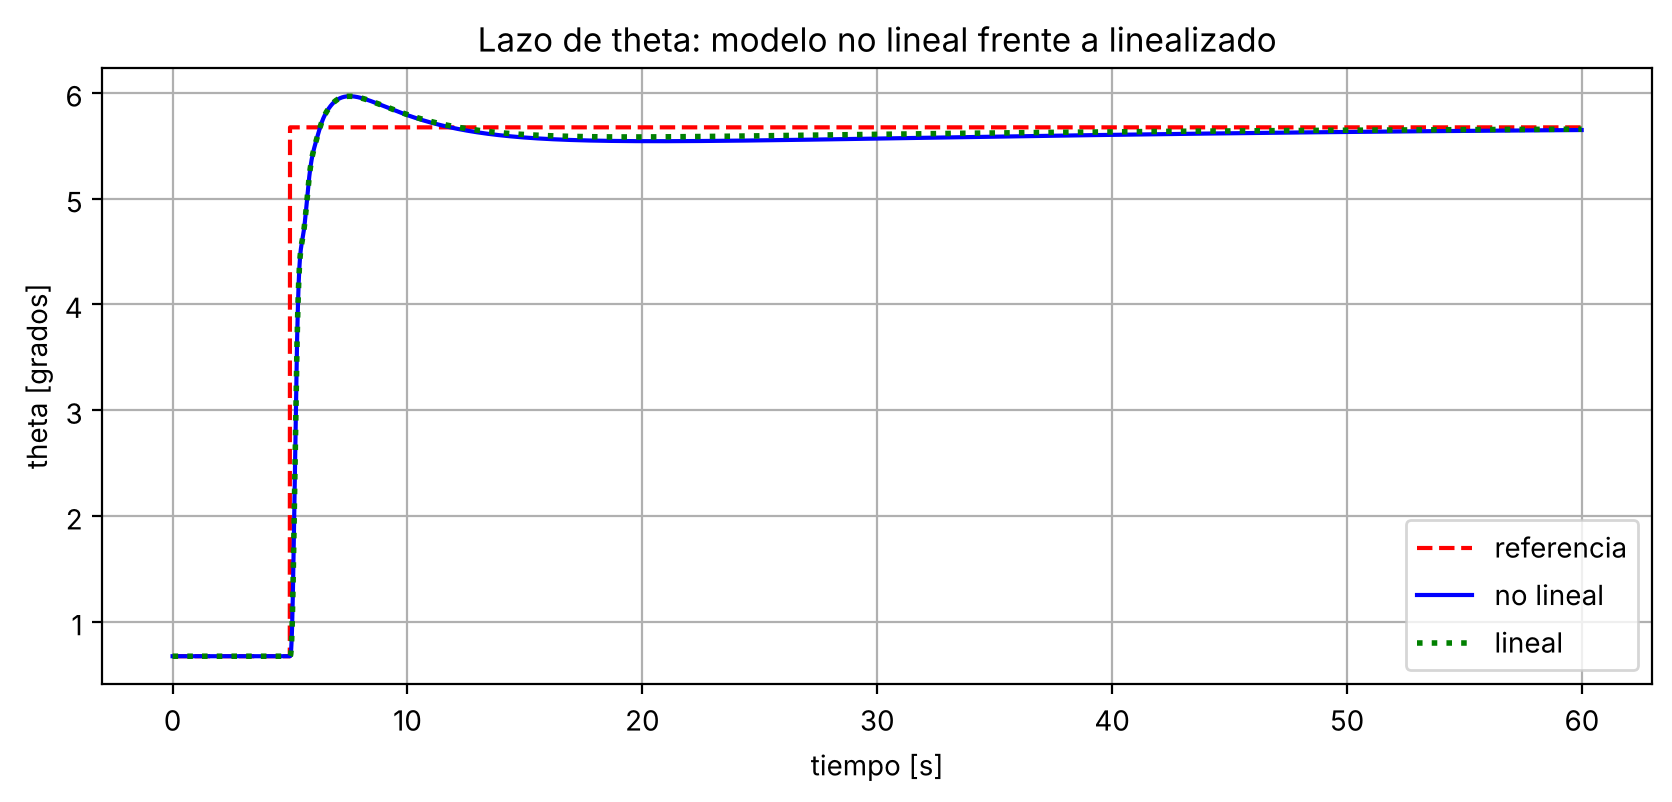

In [13]:
# Punto de equilibrio del lazo cerrado: trimado, integral = 0, theta_ref = theta_trim
X_eq = np.concatenate([x_trim, [de_trim], [0.0]])
U_eq = [theta_trim, Acc_trim]
lin_theta = ct.linearize(lazo_theta, X_eq, U_eq)

print("Polos del lazo cerrado de theta (los dos polos en 0 vienen de x y z, que solo integran la velocidad):")
with np.errstate(invalid='ignore'):      # evita un aviso de numpy por los polos en 0
    ct.damp(lin_theta)

# Respuesta del modelo lineal a las mismas entradas (en incrementos respecto al equilibrio)
y_eq = lazo_theta.output(0, X_eq, U_eq)
resp_lin = ct.forced_response(lin_theta, T, U - np.array(U_eq)[:, None])
theta_lin = resp_lin.outputs[3] + y_eq[3]

plt.figure(figsize=(10, 4))
plt.plot(T, np.degrees(theta_ref), 'r--', label='referencia')
plt.plot(T, np.degrees(senal(resp_theta, 'theta')), 'b', label='no lineal')
plt.plot(T, np.degrees(theta_lin), 'g:', linewidth=2, label='lineal')
plt.xlabel('tiempo [s]'); plt.ylabel('theta [grados]'); plt.grid(True); plt.legend()
plt.title('Lazo de theta: modelo no lineal frente a linealizado')
plt.show()

### Interpretación

- θ sigue a la referencia en 2–3 s; el término integral elimina el error estacionario.
- El timón **real** va algo retrasado respecto al **pedido** (efecto del actuador).
- Con los gases fijos, al levantar el morro el avión **sube y pierde velocidad**: controlar θ no controla ni h ni V.
- Para un escalón de 5° el modelo lineal y el no lineal casi coinciden.

Prueba a cambiar `Kp`, `Ki`, `Kd` o `tau` (por ejemplo `tau = 0.5`) y vuelve a ejecutar las celdas.

## 7. Control de altitud (*altitude hold*)

Estructura en **cascada**:

1. **Lazo externo (altitud)**: calcula la referencia de θ a partir del error de altitud
$$\theta_{ref} = \theta_{trim} + K_{p,h}\, e_h + K_{i,h} \int e_h\, dt - K_{d,h}\, \dot h,
\qquad e_h = h_{ref} - h$$
   limitada a ±θref,max para no subir o bajar demasiado brusco.
2. **Lazo interno (asiento)**: el PID de θ de la sección 6.

```
h_ref ──► [ ALT HOLD ] ──theta_ref──► [ PID ] ──de_cmd──► [ actuador ] ──Delev──► [ avión ]
              ▲                         ▲                                            │
              │                         └──────────── theta, q ──────────────────────┤
              └──────────────────────── h, h_dot ────────────────────────────────────┘
```

### Parámetros (modifícalos aquí)

In [14]:
# ===================== SIMULACIÓN =====================
t_final = 200.0     # duración [s]
dt      = 0.01      # intervalo entre puntos guardados [s]

# ===================== ACTUADOR =====================
tau     = 0.1                 # constante de tiempo del actuador [s]
de_max  = np.radians(25)      # saturación del timón [rad]

# ===================== REFERENCIA DE ALTITUD =====================
t_escalon = 5.0               # instante del escalón [s]
dh_ref    = 100.0             # cambio de altitud pedido [m]

# ===================== LAZO EXTERNO: ALTITUD =====================
Kp_h = 0.003                  # [rad theta / m]   (0.003 rad/m = 0.17 grados/m)
Ki_h = 0.00003                # [rad / (m*s)]
Kd_h = 0.03                   # [rad / (m/s)]
theta_ref_max = np.radians(10)   # límite de la theta pedida [rad]

# ===================== LAZO INTERNO: PID DE THETA =====================
Kp = 2.0
Ki = 0.5
Kd = 0.5

In [15]:
# --- Bloque de altitude hold (sistema no lineal con un estado: la integral del error de altitud) ---

def alt_hold_salida(t, x, u, p):
    """Salida: theta de referencia (limitada)."""
    h_ref, h, h_dot = u
    error_h = h_ref - h
    theta_ref = p['theta_trim'] + p['Kp_h'] * error_h + p['Ki_h'] * x[0] - p['Kd_h'] * h_dot
    return [np.clip(theta_ref, -p['theta_ref_max'], p['theta_ref_max'])]

def alt_hold_estado(t, x, u, p):
    """Derivada del estado: d(integral)/dt = error de altitud."""
    h_ref, h, h_dot = u
    return [h_ref - h]

def crear_alt_hold(Kp_h, Ki_h, Kd_h, theta_trim, theta_ref_max):
    return ct.nlsys(alt_hold_estado, alt_hold_salida,
                    inputs=['h_ref', 'h', 'h_dot'], outputs=['theta_ref'],
                    states=['int_eh'], name='alt_hold',
                    params=dict(Kp_h=Kp_h, Ki_h=Ki_h, Kd_h=Kd_h,
                                theta_trim=theta_trim, theta_ref_max=theta_ref_max))

# --- Creamos los bloques ---
actuador  = crear_actuador(tau)
pid_theta = crear_pid_theta(Kp, Ki, Kd, de_trim, de_max)
alt_hold  = crear_alt_hold(Kp_h, Ki_h, Kd_h, theta_trim, theta_ref_max)

# --- Conectamos: la salida 'theta_ref' del alt_hold va sola a la entrada 'theta_ref' del PID ---
lazo_alt = ct.interconnect(
    [avion, actuador, pid_theta, alt_hold],
    inplist=['h_ref', 'Acc'],  inputs=['h_ref', 'Acc'],
    outlist=['h', 'V', 'alpha', 'theta', 'q', 'de_cmd', 'Delev', 'theta_ref'],
    outputs=['h', 'V', 'alpha', 'theta', 'q', 'de_cmd', 'Delev', 'theta_ref'],
    name='lazo_altitud', check_unused=False)

print(lazo_alt)

<InterconnectedSystem>: lazo_altitud
Inputs (2): ['h_ref', 'Acc']
Outputs (8): ['h', 'V', 'alpha', 'theta', 'q', 'de_cmd', 'Delev', 'theta_ref']
States (9): ['avion_x', 'avion_z', 'avion_V', 'avion_alpha', 'avion_theta', 'avion_q', 'actuador_Delev_real', 'pid_theta_int_e', 'alt_hold_int_eh']

Subsystems (4):
 * <NonlinearIOSystem avion: ['Acc', 'Delev'] -> ['xpos', 'h', 'V', 'alpha',
    'theta', 'q', 'h_dot']>
 * <StateSpace actuador: ['de_cmd'] -> ['Delev']>
 * <NonlinearIOSystem pid_theta: ['theta_ref', 'theta', 'q'] -> ['de_cmd']>
 * <NonlinearIOSystem alt_hold: ['h_ref', 'h', 'h_dot'] -> ['theta_ref']>

Connections:
 * avion.Acc <- Acc
 * avion.Delev <- actuador.Delev
 * actuador.de_cmd <- pid_theta.de_cmd
 * pid_theta.theta_ref <- alt_hold.theta_ref
 * pid_theta.theta <- avion.theta
 * pid_theta.q <- avion.q
 * alt_hold.h_ref <- h_ref
 * alt_hold.h <- avion.h
 * alt_hold.h_dot <- avion.h_dot

Outputs:
 * h <- avion.h
 * V <- avion.V
 * alpha <- avion.alpha
 * theta <- avion.theta

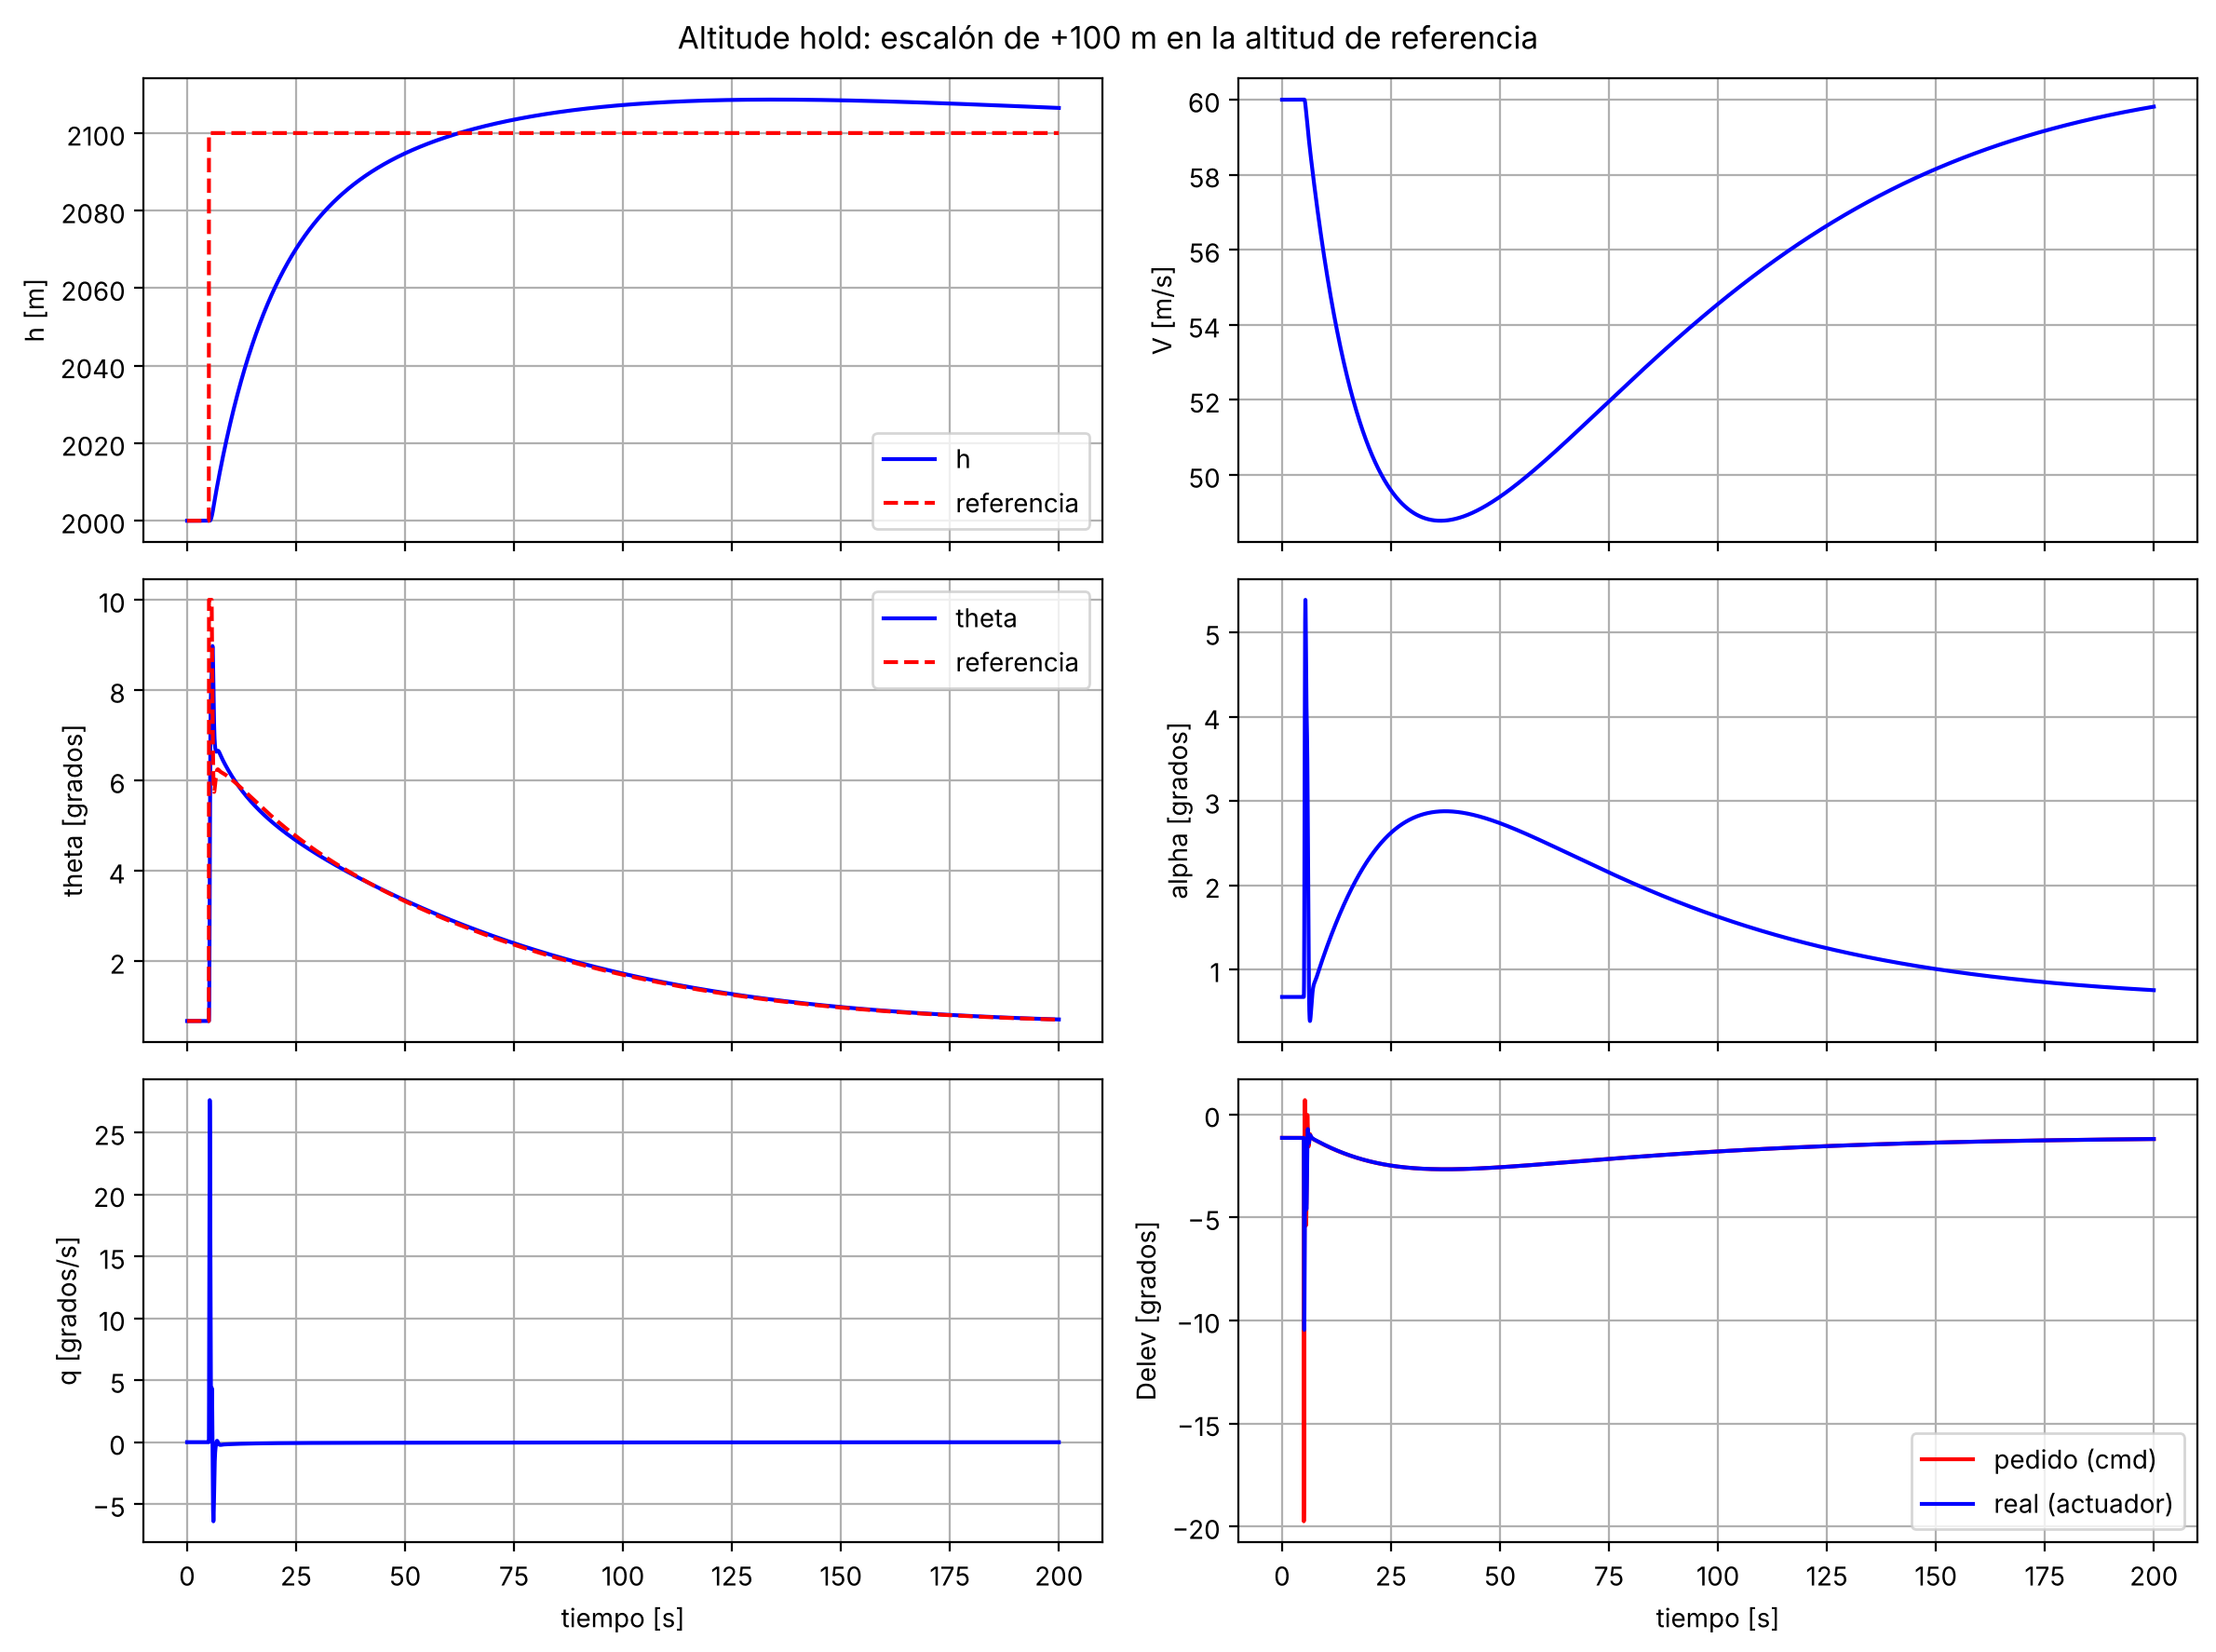

In [16]:
# --- Señales de entrada ---
T = np.arange(0, t_final, dt)
h_ref = h_crucero + dh_ref * (T >= t_escalon)
Acc = Acc_trim * np.ones_like(T)
U = np.vstack([h_ref, Acc])

# --- Estado inicial: [avión (6), actuador (1), PID (1), alt_hold (1)] ---
X0 = np.concatenate([x_trim, [de_trim], [0.0], [0.0]])

# --- Simulación no lineal ---
resp_alt = ct.input_output_response(lazo_alt, T, U, X0,
                                    solve_ivp_kwargs={'max_step': 0.01})

dibujar(resp_alt, 'Altitude hold: escalón de %+.0f m en la altitud de referencia' % dh_ref,
        theta_ref=senal(resp_alt, 'theta_ref'), h_ref=h_ref)

In [17]:
# Polos del lazo cerrado de altitud linealizado alrededor del trimado
X_eq = np.concatenate([x_trim, [de_trim], [0.0], [0.0]])
U_eq = [h_crucero, Acc_trim]
lin_alt = ct.linearize(lazo_alt, X_eq, U_eq)
print("Polos del lazo cerrado de altitud:")
with np.errstate(invalid='ignore'):
    ct.damp(lin_alt);

Polos del lazo cerrado de altitud:
    Eigenvalue (pole)       Damping     Frequency
                    0             1             0
    -4.558    +10.89j        0.3861         11.81
    -4.558    -10.89j        0.3861         11.81
    -3.221    +3.763j        0.6503         4.953
    -3.221    -3.763j        0.6503         4.953
               -0.269             1         0.269
             -0.06647             1       0.06647
  -0.01357  +0.00478j        0.9432       0.01439
  -0.01357  -0.00478j        0.9432       0.01439


### Interpretación

- El avión sube los 100 m pedidos. θref toca el límite de 10° solo un instante y después baja suavemente
  a medida que el avión se acerca a la altitud deseada; el lazo interno sigue muy bien a θref.
- La altitud tiene un pequeño sobrepaso (~8 m) y se asienta lentamente: el polo más lento del lazo cerrado
  (ver la tabla de polos) viene del fugoide y del integrador de altitud.
- **La velocidad cae** durante la subida (hasta unos 49 m/s) y se recupera al nivelar: con los gases fijos,
  la energía para subir sale de la energía cinética. En un piloto automático real, un **autothrottle**
  controlaría la velocidad con los gases mientras el *altitude hold* controla la altitud con el timón.

Prueba a cambiar:
- `dh_ref` (por ejemplo −100 m para bajar),
- `Ki_h = 0` (no hay sobrepaso, pero queda un pequeño error de altitud),
- `theta_ref_max` (limita la tasa de subida).

---
## 8. Visualización de la actitud del avión

Una animación con un avión esquemático que **sube y baja** según la altitud h y **gira** según el
ángulo de asiento θ. Además se dibujan:

- el **vector velocidad** (naranja), inclinado el ángulo de trayectoria γ = θ − α;
- un **arco rojo** alrededor del avión cuya longitud y sentido indican la velocidad de cabeceo q.

A la derecha se ven h y θ frente al tiempo, con una línea que marca el instante de la animación.

Como los ángulos son pequeños (unos pocos grados), la función permite **amplificar** el giro
(`amplificacion`) para verlo mejor; los valores numéricos del recuadro son siempre los reales.

### La función de animación

In [18]:
from matplotlib.animation import FuncAnimation   # para crear animaciones
from IPython.display import HTML                 # para mostrarlas en el cuaderno
plt.rcParams['animation.embed_limit'] = 60       # tamaño máximo de la animación [MB]

# Silueta del avión vista de lado, en ejes cuerpo: morro hacia +x, longitud ~1
SILUETA = np.array([
    [ 0.50,  0.00],   # morro
    [ 0.42,  0.05],
    [ 0.25,  0.08],   # parabrisas
    [ 0.05,  0.08],   # techo de la cabina
    [-0.32,  0.04],
    [-0.42,  0.22],   # deriva (timón de dirección)
    [-0.52,  0.22],
    [-0.52,  0.01],
    [-0.30, -0.04],
    [ 0.40, -0.05],   # vientre
])
ALA   = np.array([[0.15, 0.03], [-0.05, 0.03]])    # ala (vista de canto: una línea)
ESTAB = np.array([[-0.36, 0.03], [-0.56, 0.03]])   # estabilizador horizontal


def rotar(puntos, angulo):
    """Gira un conjunto de puntos (N x 2) un ángulo [rad] alrededor del origen."""
    c, s = np.cos(angulo), np.sin(angulo)
    R = np.array([[c, -s],
                  [s,  c]])
    return puntos @ R.T


def animar_actitud(t, h, theta, alpha, q, titulo='', h_ref=None,
                   amplificacion=1.0, n_fotogramas=150, intervalo=60):
    """Anima un avión esquemático que sube/baja con h y gira con theta.

    t, h, theta, alpha, q : vectores de la simulación (ángulos en rad, q en rad/s)
    h_ref          : vector con la altitud de referencia (opcional)
    amplificacion  : factor para exagerar los ángulos en el dibujo (1 = real)
    n_fotogramas   : número de imágenes de la animación
    intervalo      : tiempo entre imágenes al reproducir [ms]
    """
    # --- Instantes que vamos a dibujar (no hace falta dibujar todos) ---
    idx = np.linspace(0, len(t) - 1, n_fotogramas).astype(int)

    # --- Escala vertical: la variación de altitud se lleva a [-0.6, 0.6] del dibujo ---
    h0 = h[0]
    rango = max(np.max(np.abs(h - h0)), 1.0)
    if h_ref is not None:
        rango = max(rango, np.max(np.abs(h_ref - h0)))
    escala = rango / 0.6                  # metros por unidad de dibujo
    y = (h - h0) / escala                 # posición vertical del avión en el dibujo

    gamma = theta - alpha                 # ángulo de trayectoria

    # --- Figura con dos paneles ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8),
                                   gridspec_kw={'width_ratios': [1.15, 1]})

    # Panel izquierdo: la "ventana" donde se ve el avión
    ax1.set_xlim(-1.75, 1.3); ax1.set_ylim(-1.0, 1.0)   # hueco a la izquierda para el texto
    ax1.set_aspect('equal')                                   # para que los ángulos se vean bien
    ax1.set_facecolor('#EAF2FB')                              # cielo
    ax1.set_xticks([])
    marcas = np.array([-0.6, -0.3, 0, 0.3, 0.6])
    ax1.set_yticks(marcas)
    ax1.set_yticklabels(['%.0f' % (h0 + m * escala) for m in marcas])
    ax1.set_ylabel('altitud [m]')
    ax1.axhline(0, color='gray', linestyle=':', linewidth=1)  # altitud inicial
    if h_ref is not None:
        ax1.axhline((h_ref[-1] - h0) / escala, color='r', linestyle='--',
                    linewidth=1, label='h de referencia')
        ax1.legend(loc='lower right', fontsize=9)
    titulo_izq = 'Actitud'
    if amplificacion != 1:
        titulo_izq += ' (ángulos x%.0f)' % amplificacion
    ax1.set_title(titulo_izq)

    # Elementos que se moverán (se crean vacíos y se actualizan en cada fotograma)
    cuerpo = plt.Polygon(SILUETA, closed=True, color='#14213D')
    ax1.add_patch(cuerpo)
    linea_ala,   = ax1.plot([], [], color='#14213D', linewidth=5, solid_capstyle='round')
    linea_estab, = ax1.plot([], [], color='#14213D', linewidth=3, solid_capstyle='round')
    linea_eje,   = ax1.plot([], [], color='#14213D', linewidth=1, linestyle='--')  # eje del avión
    linea_vel,   = ax1.plot([], [], color='#D9782D', linewidth=2.5)               # vector velocidad
    punta_vel,   = ax1.plot([], [], color='#D9782D', marker='o', markersize=6)
    arco_q,      = ax1.plot([], [], color='#C0392B', linewidth=3)                 # indicador de q
    punta_q,     = ax1.plot([], [], color='#C0392B', marker='o', markersize=7)
    texto = ax1.text(-1.7, 0.95, '', va='top', fontsize=9, family='monospace',
                     bbox=dict(facecolor='white', alpha=0.85, edgecolor='none'))

    # Panel derecho: h y theta frente al tiempo
    ax2.plot(t, h, 'b', label='h')
    if h_ref is not None:
        ax2.plot(t, h_ref, 'b:', linewidth=1)
    ax2.set_xlabel('tiempo [s]'); ax2.set_ylabel('h [m]', color='b'); ax2.grid(True)
    ax2b = ax2.twinx()                                   # segundo eje vertical para theta
    ax2b.plot(t, np.degrees(theta), 'g', label='theta')
    ax2b.set_ylabel('theta [grados]', color='g')
    cursor = ax2.axvline(t[0], color='k', linewidth=1)   # marca el instante actual
    ax2.set_title('Evolución temporal')
    fig.suptitle(titulo)
    plt.tight_layout()

    def actualizar(k):
        """Dibuja el fotograma k."""
        i = idx[k]
        ang = amplificacion * theta[i]          # ángulo de giro del dibujo
        centro = np.array([0.0, y[i]])          # el avión sube y baja con h

        # Avión girado y desplazado
        cuerpo.set_xy(rotar(SILUETA, ang) + centro)
        ala = rotar(ALA, ang) + centro
        linea_ala.set_data(ala[:, 0], ala[:, 1])
        est = rotar(ESTAB, ang) + centro
        linea_estab.set_data(est[:, 0], est[:, 1])
        eje = rotar(np.array([[0.5, 0], [1.1, 0]]), ang) + centro
        linea_eje.set_data(eje[:, 0], eje[:, 1])

        # Vector velocidad, inclinado gamma
        g = amplificacion * gamma[i]
        fin = centro + 0.95 * np.array([np.cos(g), np.sin(g)])
        linea_vel.set_data([centro[0], fin[0]], [centro[1], fin[1]])
        punta_vel.set_data([fin[0]], [fin[1]])

        # Arco de q: empieza en el morro y su longitud es proporcional a q
        q_grados = np.degrees(q[i])
        apertura = np.radians(np.clip(6 * q_grados, -150, 150))  # 6 grados de arco por grado/s
        angulos = ang + np.linspace(0, apertura, 30)
        arco_q.set_data(0.62 * np.cos(angulos), centro[1] + 0.62 * np.sin(angulos))
        punta_q.set_data([0.62 * np.cos(angulos[-1])], [centro[1] + 0.62 * np.sin(angulos[-1])])

        # Valores numéricos reales
        texto.set_text('t     = %6.1f s\nh     = %6.1f m\ntheta = %6.2f grados\nq     = %6.2f grados/s'
                       % (t[i], h[i], np.degrees(theta[i]), q_grados))

        cursor.set_xdata([t[i], t[i]])
        return cuerpo, linea_ala, linea_estab, linea_eje, linea_vel, punta_vel, arco_q, punta_q, texto, cursor

    anim = FuncAnimation(fig, actualizar, frames=n_fotogramas, interval=intervalo, blit=True)
    plt.close(fig)               # evita que se muestre además una imagen estática
    return anim


def mostrar(anim):
    """Muestra la animación en el cuaderno.
    Si está instalado ffmpeg, como vídeo (ligero); si no, como secuencia de imágenes
    con botones de reproducción (más pesada, pero no necesita nada más)."""
    try:
        return HTML(anim.to_html5_video())
    except Exception:
        return HTML(anim.to_jshtml())

### a) Respuesta libre tras la perturbación de la sección 4

Se ve el **fugoide**: el avión sube y baja lentamente, levantando y bajando el morro.
Los ángulos se amplifican x3 para que el giro se aprecie.

In [19]:
anim_libre = animar_actitud(resp.time,
                            -resp.states[1],      # h = -z
                            resp.states[4],       # theta
                            resp.states[3],       # alpha
                            resp.states[5],       # q
                            titulo='Respuesta libre: perturbación dV = %+.1f m/s' % dV_pert,
                            amplificacion=3)
mostrar(anim_libre)

### b) Maniobra de altitude hold de la sección 7

El avión levanta el morro (pico de q al principio), sube hasta la nueva altitud y se nivela.
Los ángulos se amplifican x2.

In [20]:
anim_alt = animar_actitud(resp_alt.time,
                          senal(resp_alt, 'h'),
                          senal(resp_alt, 'theta'),
                          senal(resp_alt, 'alpha'),
                          senal(resp_alt, 'q'),
                          titulo='Altitude hold: escalón de %+.0f m' % dh_ref,
                          h_ref=h_ref,
                          amplificacion=2)
mostrar(anim_alt)

**Para guardar la animación** como GIF (por ejemplo, para una presentación):

```python
anim_alt.save('altitude_hold.gif', writer='pillow', fps=15)
```

La función `mostrar` usa vídeo si tienes **ffmpeg** instalado (`conda install ffmpeg`); si no, usa una
secuencia de imágenes con botones, que funciona igual pero hace el cuaderno más pesado.

Prueba a cambiar `amplificacion` (1 = ángulos reales) o `n_fotogramas` (más fotogramas = animación más
suave pero más pesada).